# Instructions for using the Kuva Space hyperspectral collection

## Libraries

Ensure all required packages are installed and imported.

In [1]:
import pystac_client
import rasterio
import matplotlib
import numpy as np
import os

* `pystac_client`: A Python library for working with STAC catalogs. It enables interaction with STAC services, reading catalog information, and searching for products based on specified parameters.
* `rasterio`: A geospatial raster library for reading, writing, and processing formats such as GeoTIFF and Cloud Optimized GeoTIFF (COG).
* `matplotlib`: A Python library for creating charts, plots, and raster visualizations.
* `numpy`: A library for fast numerical and array operations.

## S3 Credentials

In order to access the data from CloudFerro's catalog, authentication is required. To facilitate this, you will need to create an account in the Copernicus Data Space Ecosystem (CDSE). You can find the registration link here: https://documentation.dataspace.copernicus.eu/APIs/S3.html.

Once you have created an account, the same URL will redirect you to the section where you can generate your `S3 Credentials`. To do this, simply click the `Add Credential` button. This will allow you to define an expiration date for your credentials.

After selecting the expiration date, you will have successfully created your own S3 credentials. Please make sure to save the secret key at this point, as it will not be displayed again.

Now that you have your S3 credentials, you can use them to connect to the STAC catalog.

The only variables you need to configure are:
* `CDSE_S3_ACCESS_KEY`
* `CDSE_S3_SECRET_KEY`.

In [2]:
# os.environ["CDSE_S3_ACCESS_KEY"] = "CDSE_S3_ACCESS_KEY" # Replace with your keys!
# os.environ["CDSE_S3_SECRET_KEY"] = "CDSE_S3_SECRET_KEY" # Replace with your keys!

In [3]:
os.environ["GDAL_HTTP_TCP_KEEPALIVE"] = "YES"
os.environ["AWS_S3_ENDPOINT"] = "eodata.dataspace.copernicus.eu"
os.environ["AWS_ACCESS_KEY_ID"] = os.environ.get("CDSE_S3_ACCESS_KEY")
os.environ["AWS_SECRET_ACCESS_KEY"] = os.environ.get("CDSE_S3_SECRET_KEY")
os.environ["AWS_HTTPS"] = "YES"
os.environ["AWS_VIRTUAL_HOSTING"] = "FALSE"

## Connecting to the STAC Catalog

Connect to the Copernicus STAC catalog, available at the endpoint: https://stac.opensearch.dataspace.copernicus.eu/v1.

In [4]:
URL = "https://stac.opensearch.dataspace.copernicus.eu/v1"
cat = pystac_client.Client.open(URL)

## Defining the Area of Interest (AOI)

This is an area which includes Lake Balaton, Hungary. 

In [5]:
geom = {
    "type": "Polygon",
    "coordinates": [
      [
        [
          17.100701437883345,
          47.10614025124235
        ],
        [
          18.2873349,
          47.10614025124235
        ],
        [
          18.2873349,
          46.6525999
        ],
        [
          17.100701437883345,
          46.6525999
        ],
        [
          17.100701437883345,
          47.10614025124235
        ]
      ]
    ]
  }

## Defining Search Parameters

* `max_items`: The maximum number of results to retrieve.
* `collections`: The STAC collection.
* `datetime`: Time range in YYYY-MM-DD/YYYY-MM-DD format.
* `intersects`: The previously defined area of interest.
* `query`: A key-value pair where the key represents a specific property (e.g., eo:cloud_cover), and the value is the condition or comparison being applied.

In [6]:
params = {
    "max_items": 10,
    "collections": "ccm-hyperspectral-ref-hr",
    "datetime": "2025-09-19/2025-09-20",
    "intersects": geom,
    "query": {"processing:level": {"eq": "L2"}},
}

## Searching the Catalog

We query the catalog and convert the results into a list of STAC items.

In [9]:
items = list(cat.search(**params).items())
print(f"Items found: {len(items)}")

Items found: 2


# List available bands

Here we can see all the available bands with their wavelengths.

In [8]:
import rasterio

cog_path = items[0].assets["l2a"].href

with rasterio.open(cog_path) as src:
    print("Available wavelengths:")

    for band_index in src.indexes:
        print(f"Band {band_index}: {src.descriptions[band_index - 1]}")

Available wavelengths:
Band 1: 497.52 nm
Band 2: 505.58 nm
Band 3: 517.14 nm
Band 4: 532.45 nm
Band 5: 541.25 nm
Band 6: 560.23 nm
Band 7: 570.06 nm
Band 8: 589.77 nm
Band 9: 608.75 nm
Band 10: 625.64 nm
Band 11: 665.53 nm
Band 12: 675.41 nm
Band 13: 690.96 nm
Band 14: 710.07 nm
Band 15: 730.0 nm
Band 16: 750.0 nm
Band 17: 770.0 nm
Band 18: 790.0 nm
Band 19: 810.0 nm
Band 20: 830.0 nm
Band 21: 850.0 nm
Band 22: 870.0 nm


## NDVI

The Normalized Difference Vegetation Index (`NDVI`) is a standardized indicator of the condition and quantity of green vegetation. It is based on the difference between the near-infrared (NIR) and red bands, which respond differently to vegetation. NDVI values range from `-1` to `1`. Higher values of the index correspond to higher reflectance in the infrared range, which indicates areas covered by vegetation.

In this example, NDVI is calculated for the 19th of September 2025 around Lake Balaton.

NDVI can be calculated according to the following formula:

$$
NDVI = \frac{NIR - RED}{NIR + RED}
$$

Where:
- `NIR` is the Near-Infrared band (stacked under the number 19 in the raster).
- `RED` is the Red band (stacked under the number 10 in the raster).

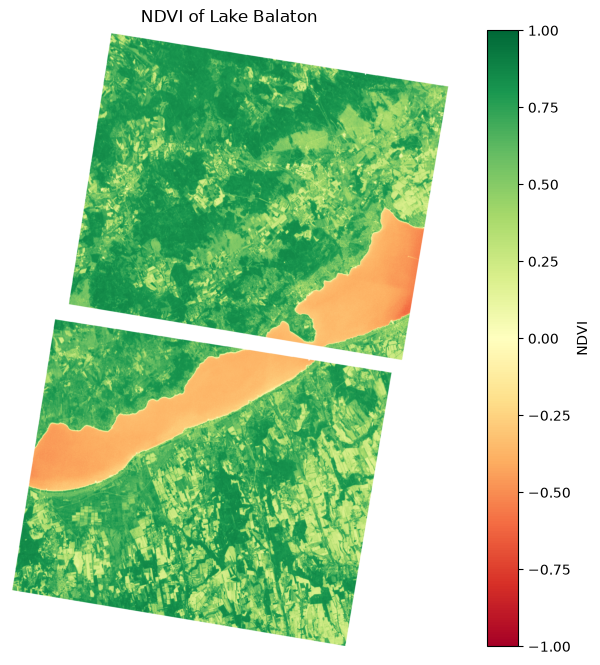

In [10]:
from rasterio.merge import merge
import matplotlib.pyplot as plt

cog_paths = [
    item.assets["l2a"].href
    for item in items
]

sources = [rasterio.open(path) for path in cog_paths]

RED_BAND = 10
NIR_BAND = 19

red_mosaic, _ = merge(
    sources,
    indexes=[RED_BAND],
    nodata=np.nan,
    dtype="float32",
)

nir_mosaic, _ = merge(
    sources,
    indexes=[NIR_BAND],
    nodata=np.nan,
    dtype="float32",
)

red = red_mosaic[0]
nir = nir_mosaic[0]

with np.errstate(divide="ignore", invalid="ignore"):
    denominator = nir + red
    ndvi = np.where(denominator != 0, (nir - red) / denominator, np.nan)

for src in sources:
    src.close()

plt.figure(figsize=(10, 8))
plt.imshow(ndvi, cmap="RdYlGn", vmin=-1, vmax=1)
plt.colorbar(label="NDVI")
plt.title("NDVI of Lake Balaton")
plt.axis("off")
plt.show()